In [1]:
import os

# --- 0. RESOURCE LIMITATION (Requested: 16 Threads) ---
# Limits the number of threads used by Numpy/Scipy/FakeSpectra to 16
# This prevents the code from hijacking the entire node.
num_cores = 20
os.environ["OMP_NUM_THREADS"] = "20"
os.environ["NUMEXPR_MAX_THREADS"] = "20"
os.environ["MKL_NUM_THREADS"] = "20"
os.environ["VECLIB_MAXIMUM_THREADS"] = "20"

import numpy as np
import h5py
import sys
import pickle
from tqdm import tqdm
import fake_spectra.spectra as spectra
import matplotlib.pyplot as plt

# --- 0. NEW CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 24,
        "axes.labelsize" : 24,
        "legend.fontsize" : 20,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 20,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 20,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)


In [2]:
# --- CONFIGURAÇÃO ---
# Baseado no seu terminal:
BASE_DIR = "/home/STORAGE"
SIMULATIONS = ["TNG50-2", "TNG50-3", "TNG50-4"]
SNAP_NUM = 25  # Confirmado pelo 'groups_025' no seu ls
HUBBLE_H = 0.6774  # Parâmetro de Hubble da TNG

print(f"🔎 Procurando o Halo mais massivo (M_200c) no Snapshot {SNAP_NUM}...\n")

for sim_name in SIMULATIONS:
    # O caminho para o catálogo de grupos (onde estão as massas)
    # Pegamos o arquivo .0.hdf5 pois os halos são ordenados por massa decrescente
    group_file = os.path.join(BASE_DIR, sim_name, f"groups_{SNAP_NUM:03d}", f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")
    
    if not os.path.exists(group_file):
        print(f"❌ Arquivo não encontrado para {sim_name}: {group_file}")
        continue
        
    try:
        with h5py.File(group_file, 'r') as f:
            # Verificar se existem grupos no arquivo
            if 'Group' not in f or 'Group_M_Crit200' not in f['Group']:
                print(f"⚠️  {sim_name}: Sem dados de 'Group_M_Crit200'.")
                continue
            
            # Ler as massas (Geralmente o índice 0 é o maior, mas vamos garantir usando max)
            # Unidade interna: 10^10 M_sun / h
            masses_code = f['Group']['Group_M_Crit200'][:]
            
            if len(masses_code) == 0:
                print(f"⚠️  {sim_name}: Arquivo de grupos vazio.")
                continue

            # Achar o máximo
            max_idx = np.argmax(masses_code)
            max_mass_code = masses_code[max_idx]
            
            # Conversão de Unidades para Massas Solares Físicas
            # M_phys = (M_code * 10^10) / h
            mass_solar = (max_mass_code * 1e10) / HUBBLE_H
            
            # Formatação bonita
            print(f"🔹 {sim_name}")
            print(f"   ↳ Halo ID (Global): {max_idx}")
            print(f"   ↳ Massa (M200c):    {mass_solar:.4e} M_sun")
            print(f"   ↳ Log10(Massa):     {np.log10(mass_solar):.2f}")
            print("-" * 40)

    except Exception as e:
        print(f"❌ Erro ao ler {sim_name}: {e}")

🔎 Procurando o Halo mais massivo (M_200c) no Snapshot 25...

🔹 TNG50-2
   ↳ Halo ID (Global): 0
   ↳ Massa (M200c):    8.8882e+12 M_sun
   ↳ Log10(Massa):     12.95
----------------------------------------
🔹 TNG50-3
   ↳ Halo ID (Global): 0
   ↳ Massa (M200c):    8.7666e+12 M_sun
   ↳ Log10(Massa):     12.94
----------------------------------------
🔹 TNG50-4
   ↳ Halo ID (Global): 0
   ↳ Massa (M200c):    9.0298e+12 M_sun
   ↳ Log10(Massa):     12.96
----------------------------------------


In [10]:
import h5py
import numpy as np
import os

# --- CONFIGURATION ---
BASE_DIR = "/home/STORAGE"
SIMULATIONS = ["TNG50-2", "TNG50-3", "TNG50-4"]
SNAP_NUM = 25  # Redshift z=3
HUBBLE_H = 0.6774 

# Define the Mass Range limits in Solar Masses (Physical)
MASS_MIN_LOG = 9
MASS_MAX_LOG = 10

mass_min = 10**MASS_MIN_LOG
mass_max = 10**MASS_MAX_LOG

print(f"🔎 Counting halos in range: 10^{MASS_MIN_LOG} < M < 10^{MASS_MAX_LOG} M_sun")
print(f"   ({mass_min:.2e} - {mass_max:.2e} M_sun)\n")

for sim_name in SIMULATIONS:
    
    # Path to the group directory
    group_dir = os.path.join(BASE_DIR, sim_name, f"groups_{SNAP_NUM:03d}")
    f0_path = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")
    
    if not os.path.exists(f0_path):
        print(f"❌ {sim_name}: File not found.")
        continue
        
    total_count = 0
    
    try:
        # 1. Read Header to get number of files (chunked data)
        with h5py.File(f0_path, 'r') as f:
            header = f['Header'].attrs
            num_files = int(header['NumFiles'])
            
        # 2. Loop over all files to count halos
        # (Although massive halos are usually in file 0, we check all to be rigorous)
        for i in range(num_files):
            file_path = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.{i}.hdf5")
            
            with h5py.File(file_path, 'r') as f:
                if 'Group' not in f or 'Group_M_Crit200' not in f['Group']:
                    continue
                
                # Load masses (Units: 10^10 M_sun / h)
                masses_code = f['Group']['Group_M_Crit200'][:]
                
                # Convert to Physical Solar Masses
                masses_phys = (masses_code * 1e10) / HUBBLE_H
                
                # Apply the condition
                # Count how many satisfy: min <= mass < max
                count_in_file = np.sum((masses_phys >= mass_min) & (masses_phys < mass_max))
                total_count += count_in_file
                
    except Exception as e:
        print(f"❌ Error processing {sim_name}: {e}")
        continue

    print(f"🔹 {sim_name}: Found {total_count} halos.")

🔎 Counting halos in range: 10^9 < M < 10^10 M_sun
   (1.00e+09 - 1.00e+10 M_sun)

🔹 TNG50-2: Found 86465 halos.
🔹 TNG50-3: Found 75624 halos.
🔹 TNG50-4: Found 14946 halos.


📂 Loading data from TNG_Resolution_Comparison_12_13.pkl...
Processing stack for all halos...


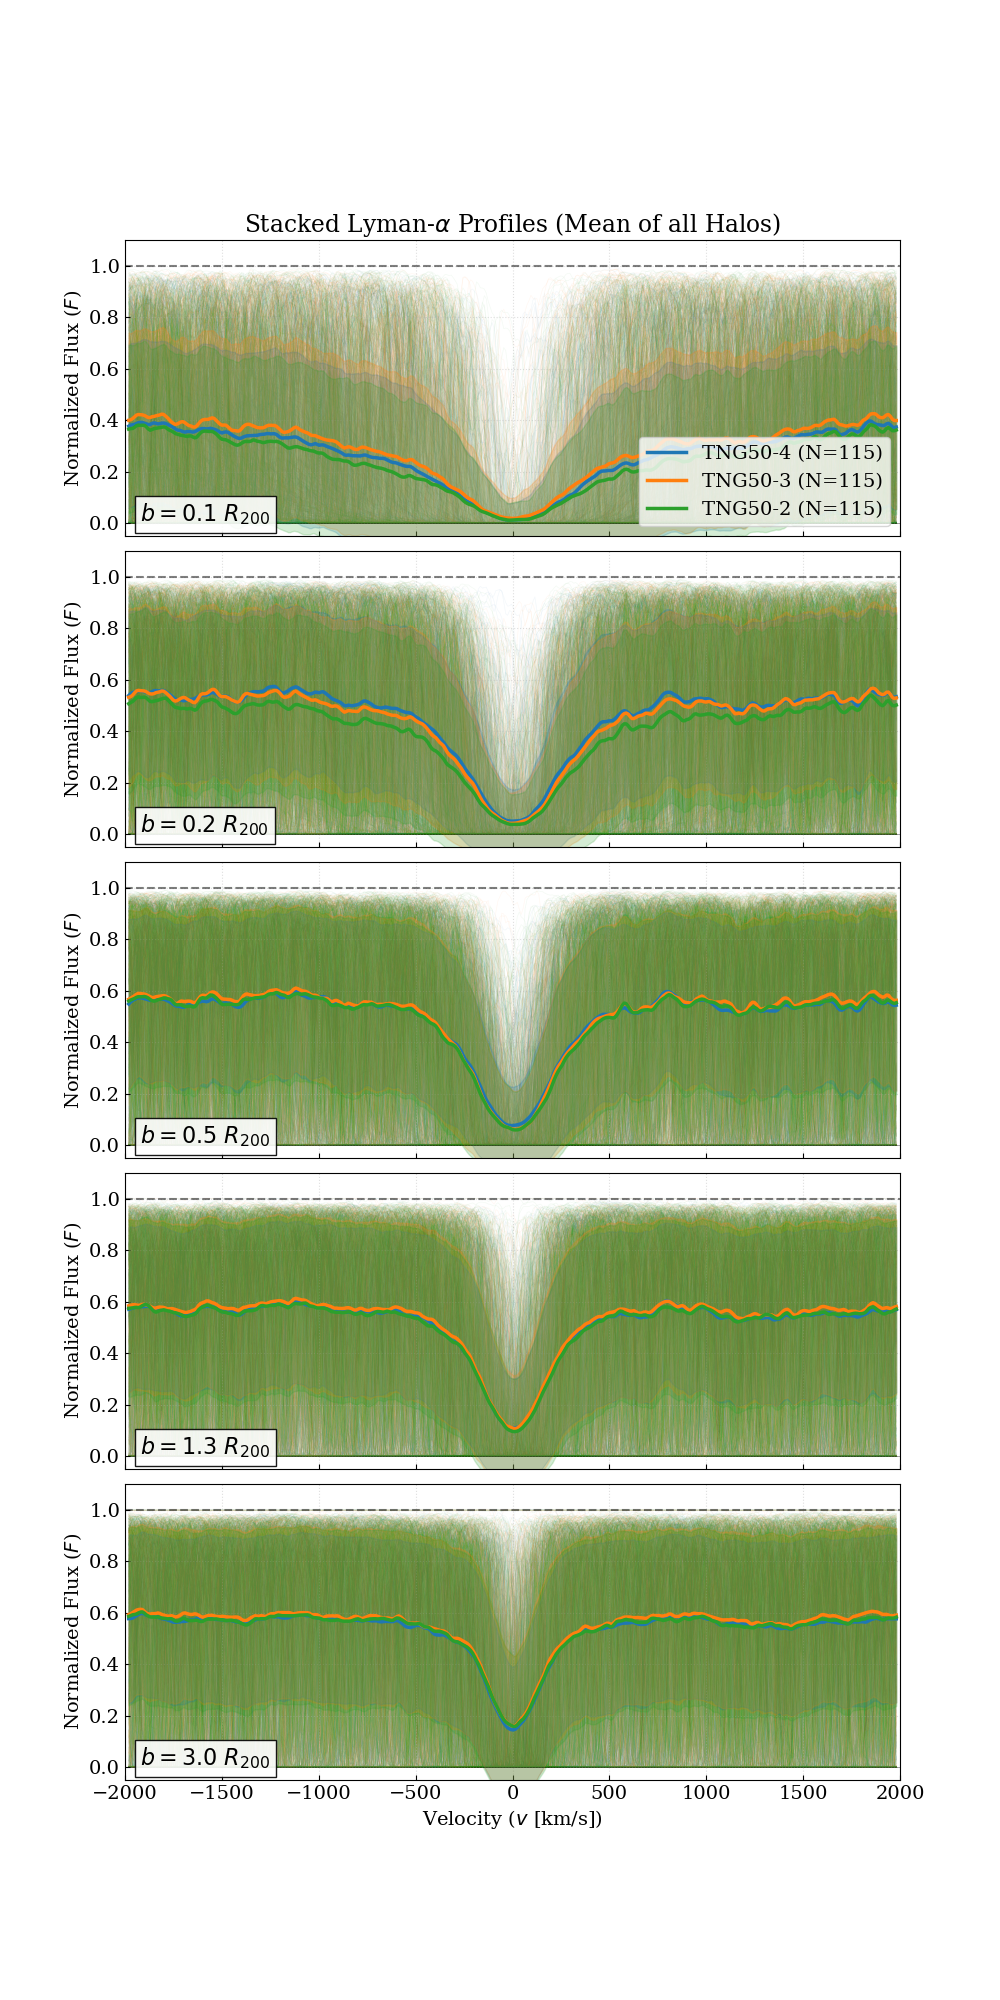

In [14]:
# --- CONFIGURATION ---
INPUT_PKL = "TNG_Resolution_Comparison_12_13.pkl"
LAMBDA_LYALPHA = 1215.67 
LIGHT_SPEED = 299792.458 

# How many thin lines to plot in the background?
# Plotting 12,000 lines (1000 halos * 12 skewers) is too heavy.
# We will calculate stats on ALL, but verify visually with a sample.
VISUAL_SAMPLE_SIZE = 500 

SIM_CONFIG = {
    "TNG50-4": {"color": "#1f77b4", "label": "TNG50-4"},
    "TNG50-3": {"color": "#ff7f0e", "label": "TNG50-3"},
    "TNG50-2": {"color": "#2ca02c", "label": "TNG50-2"}
}

def apply_plot_style():
    plt.style.use('default')
    plt.rc('font', family='serif', size=14)
    plt.rcParams['xtick.direction'] = 'in'
    plt.rcParams['ytick.direction'] = 'in'

# --- LOAD DATA ---
print(f"📂 Loading data from {INPUT_PKL}...")
with open(INPUT_PKL, 'rb') as f:
    master_data = pickle.load(f)

apply_plot_style()

# We assume 5 radii bins based on your generation code
num_radii = 5 
fig, axes = plt.subplots(nrows=num_radii, ncols=1, figsize=(10, 20), sharex=True)
plt.subplots_adjust(hspace=0.05)

print("Processing stack for all halos...")

# --- MAIN LOOP: PER RADIAL BIN ---
for i, ax in enumerate(axes):
    
    # --- INNER LOOP: PER SIMULATION ---
    for sim_name, style in SIM_CONFIG.items():
        if sim_name not in master_data: continue
            
        halos = master_data[sim_name]
        if not halos: continue
        
        # 1. GATHER DATA (The Stacking Step)
        # We need to extract the flux matrix for radius 'i' from EVERY halo.
        # radius_fluxes will be a list of arrays, each shape (12, nbins)
        radius_fluxes = []
        
        # We need the wave axis from at least one halo to convert to velocity
        # (Assuming all skewers have same binning/resolution)
        sample_wave = halos[0]['radii_data'][i]['wave']
        
        for halo in halos:
            # Check if this halo has data for this radius (sanity check)
            if i < len(halo['radii_data']):
                f_matrix = halo['radii_data'][i]['flux_matrix']
                radius_fluxes.append(f_matrix)
        
        # 2. CREATE GIANT MATRIX
        # Stack vertically. 
        # If 1000 halos, shape becomes (12000, nbins)
        if len(radius_fluxes) > 0:
            big_flux_matrix = np.vstack(radius_fluxes)
        else:
            continue
            
        # Convert Wavelength to Velocity
        vel_axis = LIGHT_SPEED * (sample_wave / LAMBDA_LYALPHA - 1)

        # 3. CALCULATE GLOBAL STATISTICS
        # These are statistically robust across the entire population
        mean_flux = np.nanmean(big_flux_matrix, axis=0)
        std_flux = np.nanstd(big_flux_matrix, axis=0)
        
        # 4. PLOT VISUAL SAMPLE (Thin Lines)
        # We randomly select indices to plot so we don't crash the viewer
        total_skewers = big_flux_matrix.shape[0]
        if total_skewers > VISUAL_SAMPLE_SIZE:
            indices = np.random.choice(total_skewers, VISUAL_SAMPLE_SIZE, replace=False)
            sample_matrix = big_flux_matrix[indices]
        else:
            sample_matrix = big_flux_matrix

        # Plot the sample thin lines
        for flux in sample_matrix:
            ax.plot(vel_axis, flux, color=style['color'], 
                    alpha=0.05, linewidth=0.5, zorder=1) # Very transparent
            
        # 5. PLOT GLOBAL MEAN AND STD
        label_text = f"{style['label']} (N={len(halos)})" if i == 0 else ""
        
        ax.plot(vel_axis, mean_flux, color=style['color'], 
                linewidth=2.5, label=label_text, zorder=3)
        
        ax.fill_between(vel_axis, mean_flux - std_flux, mean_flux + std_flux,
                        color=style['color'], alpha=0.2, zorder=2)
        
        # Capture impact parameter label from first halo
        r_mult = halos[0]['radii_data'][i]['r_mult']

    # --- FORMATTING ---
    ax.text(0.02, 0.05, f"$b = {r_mult:.1f} \ R_{{200}}$", transform=ax.transAxes,
            fontsize=16, fontweight='bold', bbox=dict(facecolor='white', alpha=0.9))
    
    ax.set_ylabel(r"Normalized Flux ($F$)")
    ax.set_ylim(-0.05, 1.1)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.axhline(1, color='k', ls='--', alpha=0.5)
    ax.axhline(0, color='k', ls='-', lw=0.5, alpha=0.5)

axes[-1].set_xlabel(r"Velocity ($v$ [km/s])")
axes[-1].set_xlim(-2000, 2000) # Zoom in to relevant region
axes[0].legend(loc="lower right")
axes[0].set_title(r"Stacked Lyman-$\alpha$ Profiles (Mean of all Halos)")
plt.savefig("Stacked_LyA_Profiles.png", dpi=300, bbox_inches="tight")

plt.show()

📂 Loading pickle data...
🔗 Performing Positional Cross-Match...
   ↳ Found 37 candidates in TNG50-4 (Reference).
   ↳ Reading TNG50-3 and TNG50-2 catalogs...
   ✅ Match Found!
      IDs: L4=3 | L3=3 | L2=3
      Mass: 3.02e+12 M_sun
      Dists: 9.49 kpc (L3), 9.25 kpc (L2)
   ✅ Match Found!
      IDs: L4=1 | L3=1 | L2=1
      Mass: 6.16e+12 M_sun
      Dists: 6.13 kpc (L3), 3.26 kpc (L2)
   ✅ Match Found!
      IDs: L4=2 | L3=2 | L2=2
      Mass: 6.28e+12 M_sun
      Dists: 12.56 kpc (L3), 4.52 kpc (L2)
   ✅ Match Found!
      IDs: L4=0 | L3=0 | L2=0
      Mass: 9.03e+12 M_sun
      Dists: 5.89 kpc (L3), 12.17 kpc (L2)

🎨 Generating Plots for 4 Matched Groups...


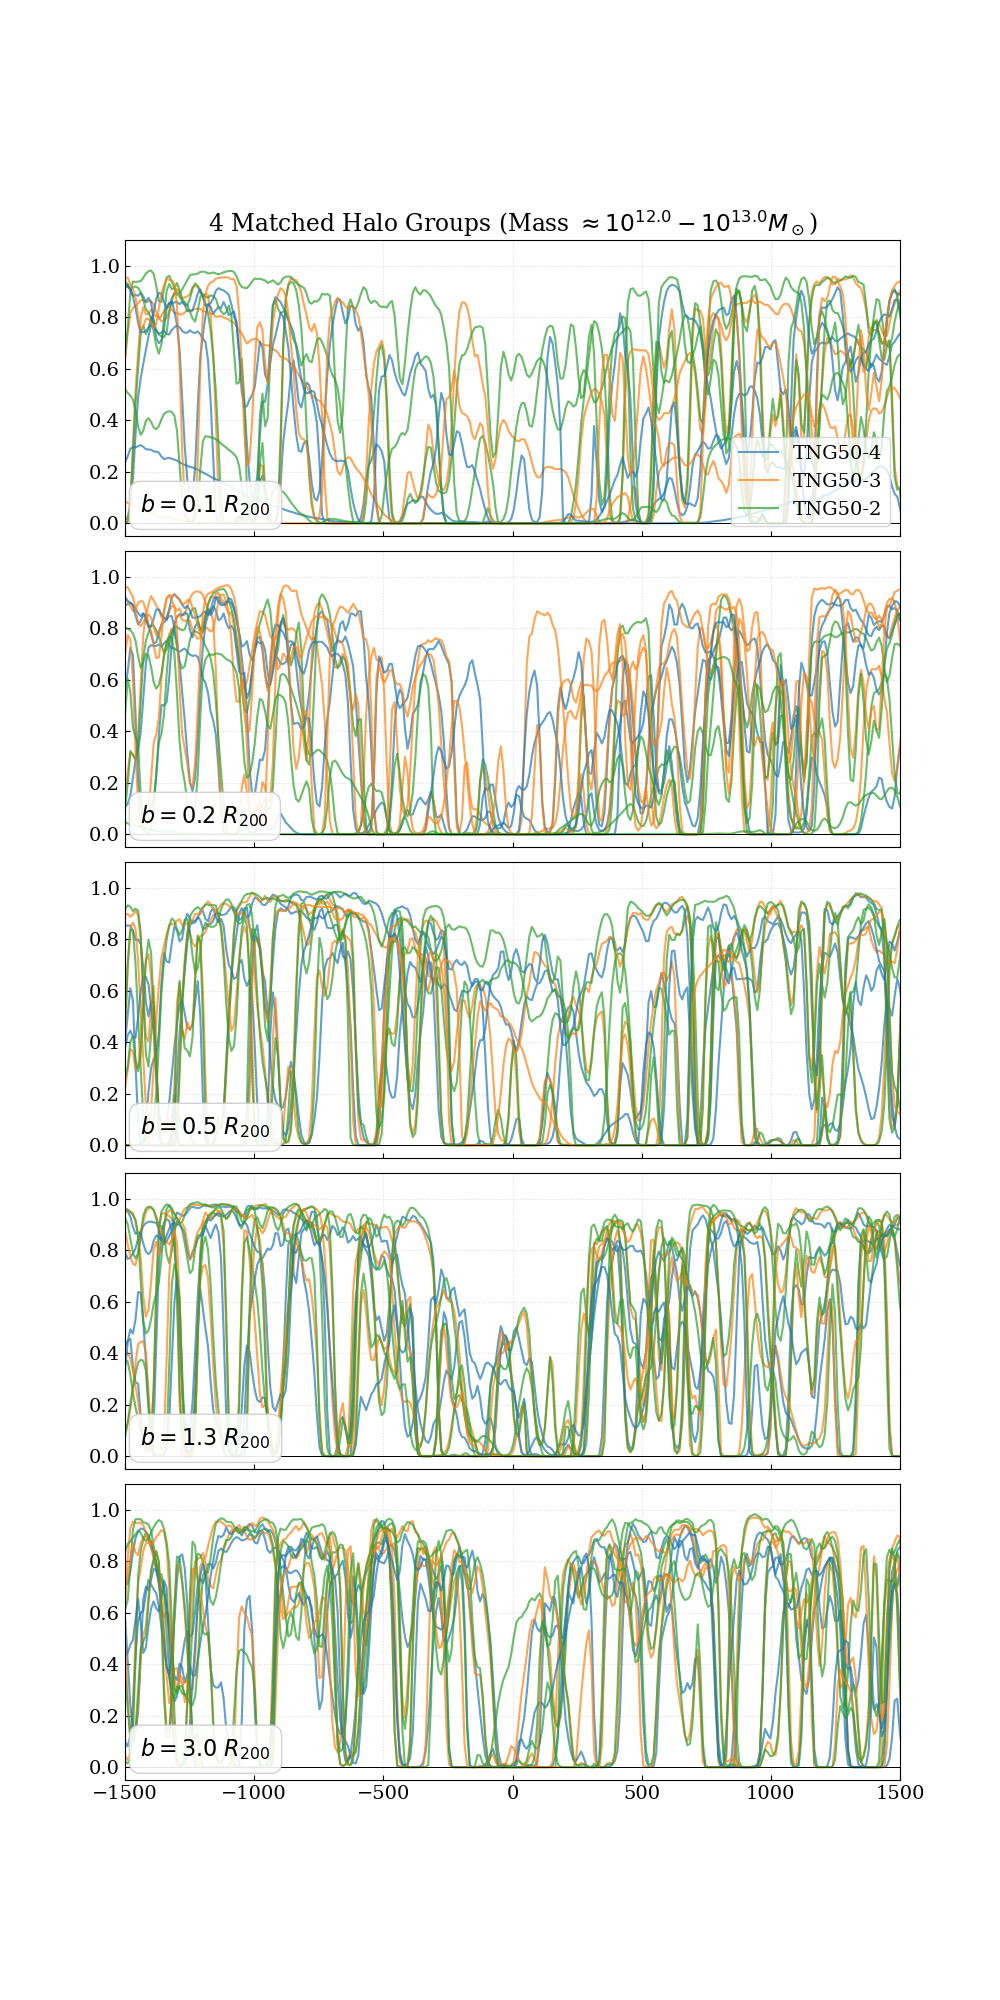

In [18]:
import pickle
import numpy as np
import h5py
import os
import matplotlib.pyplot as plt

# ================= CONFIGURATION =================
INPUT_PKL = "TNG_Resolution_Comparison_12_13.pkl" 
BASE_DIR = "/home/STORAGE"
SNAP_NUM = 25
HUBBLE_H = 0.6774

# Adjusted Range to try and find more halos
# (Try relaxing this if you still only find 1 halo)
MASS_MIN = 10**12.0 
MASS_MAX = 10**13.0

N_GROUPS_TO_PLOT = 5
MATCH_TOLERANCE_CKPC = 50.0 

SIM_CONFIG = {
    "TNG50-4": {"color": "#1f77b4", "label": "TNG50-4", "linestyle": "-"}, 
    "TNG50-3": {"color": "#ff7f0e", "label": "TNG50-3", "linestyle": "-"}, 
    "TNG50-2": {"color": "#2ca02c", "label": "TNG50-2", "linestyle": "-"}  
}

# --- HELPERS ---
def get_halo_pos_mass_from_disk(sim_name, halo_id):
    group_dir = os.path.join(BASE_DIR, sim_name, f"groups_{SNAP_NUM:03d}")
    f0_path = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")
    
    # Try file 0 first (fastest for massive halos)
    with h5py.File(f0_path, 'r') as f:
        n_groups_file = f['Header'].attrs['Ngroups_ThisFile']
        if halo_id < n_groups_file:
            pos = f['Group']['GroupPos'][halo_id]
            mass = f['Group']['Group_M_Crit200'][halo_id] * 1e10 / HUBBLE_H
            return pos, mass
    
    # If not in file 0, we simply skip (safe for your massive halos context)
    return None, None

def load_all_halos_for_matching(sim_name):
    group_dir = os.path.join(BASE_DIR, sim_name, f"groups_{SNAP_NUM:03d}")
    f0_path = os.path.join(group_dir, f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5")
    with h5py.File(f0_path, 'r') as f:
        positions = f['Group']['GroupPos'][:]
        masses = f['Group']['Group_M_Crit200'][:] * 1e10 / HUBBLE_H
        ids = np.arange(len(positions))
    return ids, positions, masses

# ================= 1. LOAD DATA =================
print(f"📂 Loading pickle data...")
if not os.path.exists(INPUT_PKL):
    INPUT_PKL = "TNG_Resolution_Comparison.pkl" 
    print(f"⚠️  Loading {INPUT_PKL} instead.")

with open(INPUT_PKL, 'rb') as f:
    master_data = pickle.load(f)

# ================= 2. CROSS-MATCHING LOGIC =================
print("🔗 Performing Positional Cross-Match...")

ref_candidates = [
    h for h in master_data["TNG50-4"] 
    if (h['mass'] >= MASS_MIN) and (h['mass'] <= MASS_MAX)
]
matched_trios = [] 

print(f"   ↳ Found {len(ref_candidates)} candidates in TNG50-4 (Reference).")
print("   ↳ Reading TNG50-3 and TNG50-2 catalogs...")
ids_3, pos_3, mass_3 = load_all_halos_for_matching("TNG50-3")
ids_2, pos_2, mass_2 = load_all_halos_for_matching("TNG50-2")

np.random.seed(42)
np.random.shuffle(ref_candidates) 

for ref_halo in ref_candidates:
    if len(matched_trios) >= N_GROUPS_TO_PLOT: break
    
    ref_pos, _ = get_halo_pos_mass_from_disk("TNG50-4", ref_halo['id'])
    if ref_pos is None: continue
    
    # Match TNG50-3
    dist_3 = np.linalg.norm(pos_3 - ref_pos, axis=1)
    match_idx_3 = np.argmin(dist_3)
    min_dist_3 = dist_3[match_idx_3]
    
    # Match TNG50-2
    dist_2 = np.linalg.norm(pos_2 - ref_pos, axis=1)
    match_idx_2 = np.argmin(dist_2)
    min_dist_2 = dist_2[match_idx_2]
    
    if min_dist_3 < MATCH_TOLERANCE_CKPC and min_dist_2 < MATCH_TOLERANCE_CKPC:
        
        # Retrieve Objects from Pickle
        def find_in_pickle(sim, hid):
            for h in master_data[sim]:
                if h['id'] == hid: return h
            return None
        
        halo_3_obj = find_in_pickle("TNG50-3", ids_3[match_idx_3])
        halo_2_obj = find_in_pickle("TNG50-2", ids_2[match_idx_2])
        
        if halo_3_obj and halo_2_obj:
            matched_trios.append({
                "TNG50-4": ref_halo,
                "TNG50-3": halo_3_obj,
                "TNG50-2": halo_2_obj
            })
            print(f"   ✅ Match Found!")
            print(f"      IDs: L4={ref_halo['id']} | L3={halo_3_obj['id']} | L2={halo_2_obj['id']}")
            print(f"      Mass: {ref_halo['mass']:.2e} M_sun")
            print(f"      Dists: {min_dist_3:.2f} kpc (L3), {min_dist_2:.2f} kpc (L2)")

# ================= 3. PLOTTING LOGIC =================
if not matched_trios:
    print("\n⚠️  No matches found. Try widening the mass range.")
else:
    num_radii = 5 
    fig, axes = plt.subplots(nrows=num_radii, ncols=1, figsize=(10, 20), sharex=True)
    plt.subplots_adjust(hspace=0.05)
    
    LIGHT_SPEED = 299792.458
    LAMBDA_LYALPHA = 1215.67

    print(f"\n🎨 Generating Plots for {len(matched_trios)} Matched Groups...")
    
    # Iterate over found groups
    for group_idx, trio in enumerate(matched_trios):
        
        # For each panel, pick a random viewing angle
        # BUT use the same angle for all 3 sims in that group
        viewing_angles = np.random.randint(0, 12, size=num_radii)
        
        for i, ax in enumerate(axes):
            current_r_mult = None
            angle_idx = viewing_angles[i]
            
            for sim_name, style in SIM_CONFIG.items():
                halo = trio[sim_name]
                
                if i < len(halo['radii_data']):
                    r_data = halo['radii_data'][i]
                    current_r_mult = r_data['r_mult']
                    flux_matrix = r_data['flux_matrix']
                    
                    skewer_flux = flux_matrix[angle_idx]
                    
                    # Velocity Axis
                    sample_wave = trio['TNG50-4']['radii_data'][i]['wave']
                    vel_axis = LIGHT_SPEED * (sample_wave / LAMBDA_LYALPHA - 1)
                    
                    # Label only for the first group to avoid legend clutter
                    label = style['label'] if (i == 0 and group_idx == 0) else None
                    
                    # Plotting
                    # Use slightly transparent lines so multiple groups can be seen
                    ax.plot(vel_axis, skewer_flux, 
                            color=style['color'], linestyle=style['linestyle'],
                            linewidth=1.5, alpha=0.7, label=label)

            if current_r_mult is not None and group_idx == 0:
                ax.text(0.02, 0.08, f"$b = {current_r_mult:.1f} \ R_{{200}}$", transform=ax.transAxes,
                        fontsize=16, fontweight='bold', 
                        bbox=dict(facecolor='white', alpha=0.9, edgecolor='#cccccc', boxstyle='round,pad=0.5'))

            ax.set_ylim(-0.05, 1.1) 
            ax.grid(True, linestyle=':', alpha=0.4)
            ax.axhline(0, color='k', ls='-', lw=0.5)

    axes[0].legend(loc="lower right")
    axes[-1].set_xlim(-1500, 1500)
    title_text = f"{len(matched_trios)} Matched Halo Groups (Mass $\\approx 10^{{{np.log10(MASS_MIN):.1f}}} - 10^{{{np.log10(MASS_MAX):.1f}}} M_\\odot$)"
    axes[0].set_title(title_text)
    plt.show()

### How many gas particles the skewer crosses?

🔎 Shooting CENTRAL SKEWERS and counting particles...

🔹 Processing TNG50-4...
Reloading from snapshot (will save to:  /home/STORAGE/TNG50-4/snapdir_025/spectra.hdf5  )
1  sightlines. resolution:  1.000137852803097  z= 3.008131071630377
rank = 0 | Interpolation 9.1 percent done
rank = 0 | Interpolation 18.2 percent done
rank = 0 | Interpolation 27.3 percent done
rank = 0 | Interpolation 36.4 percent done
rank = 0 | Interpolation 45.5 percent done
rank = 0 | Interpolation 54.5 percent done
rank = 0 | Interpolation 63.6 percent done
rank = 0 | Interpolation 72.7 percent done
rank = 0 | Interpolation 81.8 percent done
rank = 0 | Interpolation 90.9 percent done
   ✅ Intercepted: 732 gas particles.
🔹 Processing TNG50-3...
Reloading from snapshot (will save to:  /home/STORAGE/TNG50-3/snapdir_025/spectra.hdf5  )
1  sightlines. resolution:  1.000137852803097  z= 3.008131071630377
rank = 0 | Interpolation 9.1 percent done
rank = 0 | Interpolation 18.2 percent done
rank = 0 | Interpolation 27.3 p

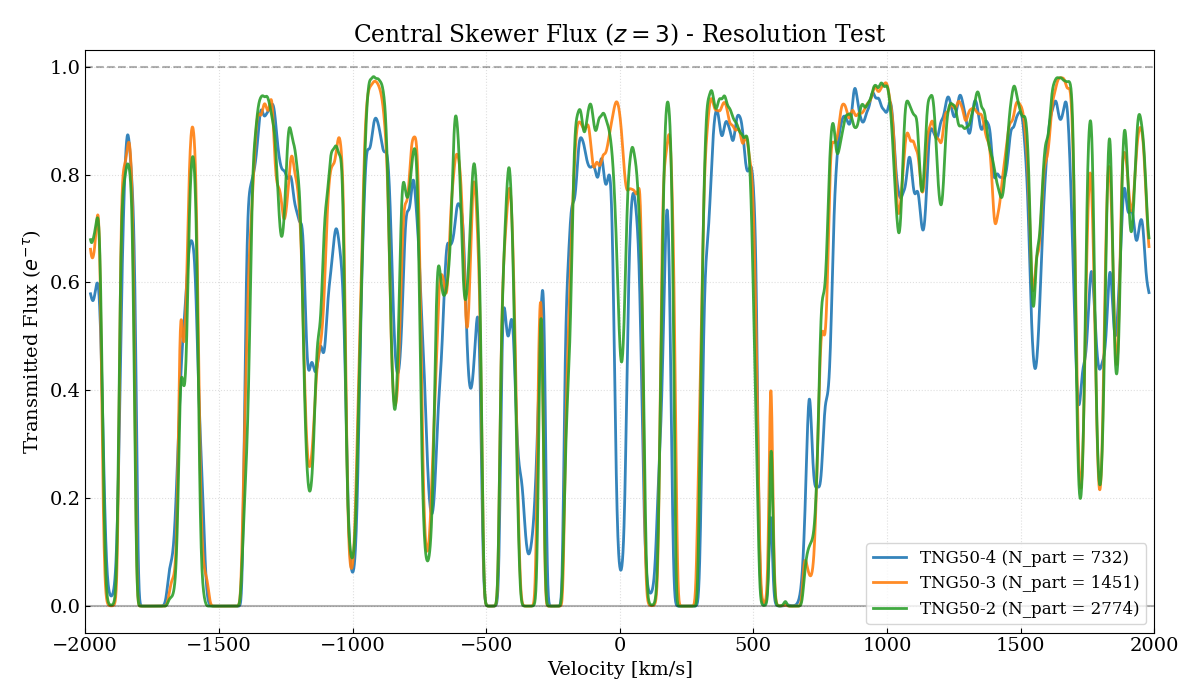

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
import os
from fake_spectra import spectra

# ================= CONFIGURATION =================
BASE_DIR = "/home/STORAGE"
SNAP_NUM = 25

# Simulation Config
SIMS = [
    {"name": "TNG50-4", "color": "#1f77b4"}, # Low Res
    {"name": "TNG50-3", "color": "#ff7f0e"}, # Med Res
    {"name": "TNG50-2", "color": "#2ca02c"}  # High Res
]

# Physics Config
PROJECTION_AXIS = 3  # Z-axis
ION = 1      # HI
LINE = 1215  # Angstroms

# ================= MAIN LOOP =================
plt.figure(figsize=(12, 7))

print(f"🔎 Shooting CENTRAL SKEWERS and counting particles...\n")

for sim in SIMS:
    sim_name = sim['name']
    print(f"🔹 Processing {sim_name}...")
    
    # 1. Get BoxSize to find center
    snap_file = os.path.join(BASE_DIR, sim_name, f"snapdir_{SNAP_NUM:03d}", f"snap_{SNAP_NUM:03d}.0.hdf5")
    try:
        with h5py.File(snap_file, 'r') as f:
            header = f['Header'].attrs
            box_size = header['BoxSize'] 
    except Exception as e:
        print(f"   ⚠️ Could not read header: {e}. Defaulting to 35000.")
        box_size = 35000.0

    center = box_size / 2.0
    # 3D Coordinates [x, y, z] required by this version of fake_spectra
    cofm = np.array([[center, center, center]]) 
    
    # 2. Initialize Fake Spectra
    try:
        # reload_file=True: Forces recalculation (ignoring old files)
        spec = spectra.Spectra(SNAP_NUM, os.path.join(BASE_DIR, sim_name), 
                               cofm=cofm, axis=PROJECTION_AXIS, res=1.0, 
                               units='Gwollum', 
                               reload_file=True) 
        
        # --- THE CRITICAL HACK ---
        # Forces fake_spectra to keep the particle index cache in memory
        spec.cofm_final = True 
        # -------------------------
        
        # 3. Compute Tau (Triggers particle finding)
        tau = spec.get_tau("H", ION, LINE)
        
        # 4. Count Particles across all segments
        n_particles = 0
        if hasattr(spec, 'part_ind'):
            # spec.part_ind is a dict: {segment_id: [list_of_indices]}
            for seg_id in spec.part_ind:
                n_particles += len(spec.part_ind[seg_id])
        
        # 5. Process Flux and Velocity
        flux = np.exp(-tau[0])
        
        # Construct Velocity Axis centered at 0
        n_bins = len(flux)
        vel_axis = np.arange(n_bins) * spec.dvbin
        vel_axis = vel_axis - (vel_axis.max() / 2)

        print(f"   ✅ Intercepted: {n_particles} gas particles.")
        
        # 6. Plot
        plt.plot(vel_axis, flux, 
                 color=sim['color'], 
                 label=f"{sim_name} (N_part = {n_particles})", 
                 linewidth=2, alpha=0.9)

    except Exception as e:
        print(f"   ❌ Error in {sim_name}: {e}")

# ================= FORMATTING =================
plt.title(f"Central Skewer Flux ($z=3$) - Resolution Test")
plt.xlabel("Velocity [km/s]", fontsize=14)
plt.ylabel(r"Transmitted Flux ($e^{-\tau}$)", fontsize=14)
plt.axhline(1, color='k', linestyle='--', alpha=0.3)
plt.axhline(0, color='k', linestyle='-', alpha=0.3)

# Add grid and legend
plt.grid(True, linestyle=':', alpha=0.4)
plt.legend(fontsize=12, loc='lower right', frameon=True)

plt.xlim(-2000, 2000)
plt.tight_layout()
plt.show()